# M7.2 · 期权定价与 Greeks

> 期权定价用 Black-Scholes 解析公式或二叉树数值方法，Greeks 刻画价格对标的、
> 波动率、时间等的敏感度，是对冲与风险管理的基础。

## 一、公式（Black-Scholes）

$$d_1=\frac{\ln(S/K)+(r+\sigma^2/2)T}{\sigma\sqrt T},\quad d_2=d_1-\sigma\sqrt T$$
$$C=S\Phi(d_1)-Ke^{-rT}\Phi(d_2)$$

Greeks：Delta=$\Phi(d_1)$，Gamma=$\phi(d_1)/(S\sigma\sqrt T)$，Vega=$S\phi(d_1)\sqrt T$。

## 二、定价与对冲

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np
from deriv_lab import options
S, K, r, sigma, T = 100, 100, 0.03, 0.2, 0.5
c = options.bs_price(S, K, r, sigma, T, 'call')
p = options.bs_price(S, K, r, sigma, T, 'put')
print('call=%.4f put=%.4f put-call平价差=%.4f' % (c, p, c-p-(S-K*np.exp(-r*T))))
g = options.bs_greeks(S, K, r, sigma, T)
print('delta=%.3f gamma=%.4f vega=%.4f' % (g['delta'], g['gamma'], g['vega']))
print('二叉树=%.4f 与BS差异=%.4f' % (options.binomial_price(S,K,r,sigma,T,200),
      abs(options.binomial_price(S,K,r,sigma,T,200)-c)))
print('反解隐含波动率=%.4f' % options.implied_vol(c, S, K, r, T))

call=6.3710 put=4.8822 put-call平价差=0.0000
delta=0.570 gamma=0.0278 vega=0.2777
二叉树=6.3640 与BS差异=0.0070
反解隐含波动率=0.2000


## 三、可视化：Greeks 随标的变化

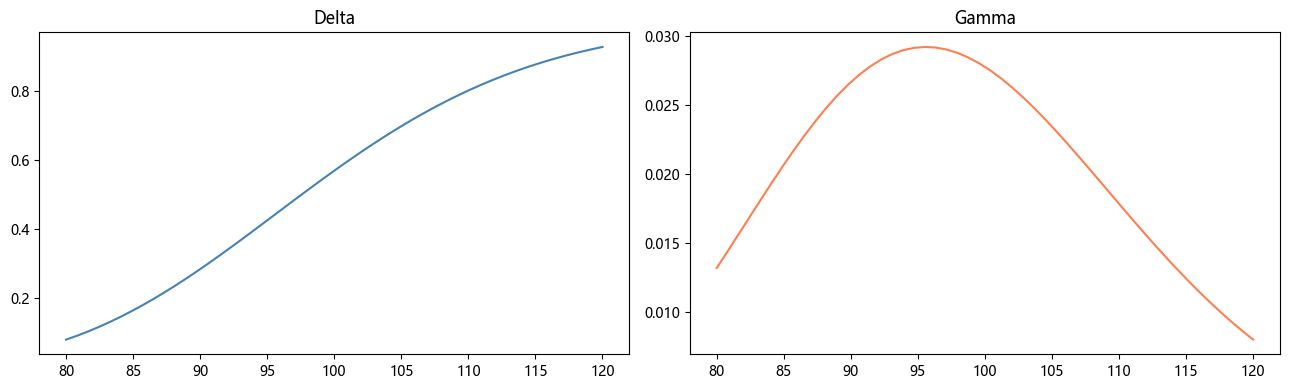

In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
spots = np.linspace(80, 120, 50)
deltas = [options.bs_greeks(s, K, r, sigma, T)['delta'] for s in spots]
gammas = [options.bs_greeks(s, K, r, sigma, T)['gamma'] for s in spots]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(spots, deltas, color='steelblue'); ax[0].set_title('Delta')
ax[1].plot(spots, gammas, color='coral'); ax[1].set_title('Gamma')
plt.tight_layout(); plt.show()

## 四、面试要点

- **BS 的核心假设？** 标的几何布朗运动、恒定波动率、无交易成本、可连续对冲、无套利。
- **put-call 平价？** $C-P=S-Ke^{-rT}$，违反即有套利机会。
- **Delta 对冲怎么做？** 按 Delta 持有反向标的头寸使组合 Delta 中性，需动态再平衡。
- **隐含波动率如何反解？** 市场价格没有解析反解，用二分法/牛顿法数值求解。

## 五、练习

1. 实现美式期权二叉树（提前行权）。
2. 验证 Delta 对冲的损益与 Gamma 的关系。
3. 比较二叉树收敛速度与步数。
4. 用真实期权链计算隐含波动率。